# 

In [2]:
from qiskit import QuantumCircuit
from qiskit.transpiler import generate_preset_pass_manager
from qiskit_ibm_runtime import QiskitRuntimeService, SamplerV2 as Sampler
from qiskit.visualization import plot_histogram
import matplotlib.pyplot as plt
import numpy as np

In [4]:
service = QiskitRuntimeService()

print("Connected to IBM Quantum!")
print("Activated instance:")

Connected to IBM Quantum!
Activated instance:


In [9]:
backend = service.backend("ibm_fez")

print("Selected backend:", backend.name)

Selected backend: ibm_fez


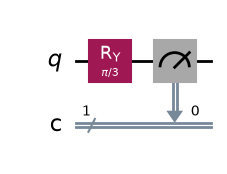

In [5]:
qc_zero = QuantumCircuit(1, 1)

qc_zero.ry(np.pi / 3, 0)
qc_zero.measure(0, 0)

display(qc_zero.draw("mpl"))


For an $RY(\theta)$ gate applied to $|0\rangle$:

$$
P(0) = \cos^2(\theta/2)
$$

$$
P(1) = \sin^2(\theta/2)
$$

For $\theta = \pi/3$:

$$
P(0) = \cos^2(\pi/6) = 0.75
$$

$$
P(1) = \sin^2(\pi/6) = 0.25
$$
Prediction: Approximately 75% 0 and 25% 1, or around 75 zeros and 25 ones in 100 shots.

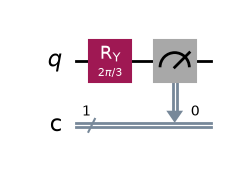

In [10]:
qc_one = QuantumCircuit(1, 1)

qc_one.ry(2 * np.pi / 3, 0)

qc_one.measure(0, 0)

display(qc_one.draw("mpl"))

Prediction: Approximately 25% 0 and 75% 1, or around 25 zeros and 75 ones in 100 shots.

In [11]:
circuits = [qc_zero, qc_one]

pass_manager = generate_preset_pass_manager(
    backend=backend,
    optimization_level=1
)

isa_circuits = pass_manager.run(circuits)

print("Both circuits are ready for execution.")

Both circuits are ready for execution.


In [14]:
sampler = Sampler(mode=backend)

job = sampler.run(isa_circuits, shots=100)

print("Job ID:", job.job_id())

result = job.result()

print("Execution completed!")

C:\Users\surya\AppData\Local\Temp\ipykernel_14196\2032286216.py:1: DeprecationWarning: The SamplerV2 class is deprecated as of qiskit-ibm-runtime 0.50.0 and will be removed no sooner than 3 months after the release date. `qiskit_ibm_runtime.executor_sampler.Sampler` provides a new Sampler implementation that runs all the pre- and post-processing in the client side. The top-level `qiskit_ibm_runtime.Sampler` import will be updated to point to the client-side sampler in an upcoming release, with the legacy Sampler being available until the deprecation is completed.
  sampler = Sampler(mode=backend)


Job ID: db5ofuclf4us73c4be20
Execution completed!


In [15]:
counts_zero = result[0].data.c.get_counts()
counts_one = result[1].data.c.get_counts()

print("Circuit biased toward 0:", counts_zero)
print("Circuit biased toward 1:", counts_one)

Circuit biased toward 0: {'0': 78, '1': 22}
Circuit biased toward 1: {'0': 25, '1': 75}


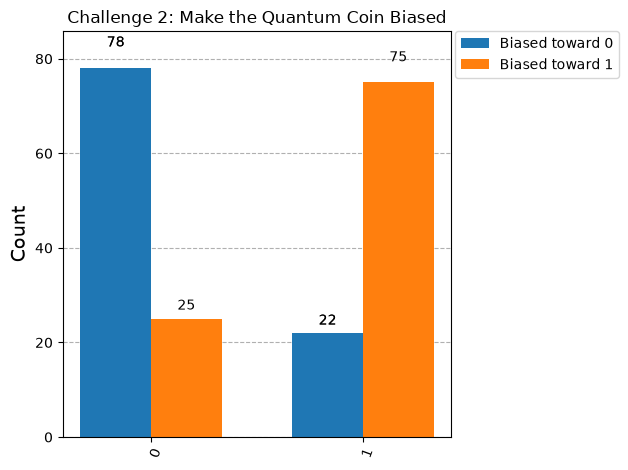

In [16]:
%matplotlib inline

fig = plot_histogram(
    [counts_zero, counts_one],
    legend=["Biased toward 0", "Biased toward 1"],
    title="Challenge 2: Make the Quantum Coin Biased"
)

plt.show()

$Challenge Answer:$\
Quantum gates change a qubit's state and probability amplitudes. Rotation gates such as RY control these amplitudes, changing the probabilities of measuring 0 or 1. By choosing different rotation angles, we can create a biased quantum coin that favors either outcome. For example, RY(π/3) ideally gives a 75% probability of measuring 0 and a 25% probability of measuring 1. Actual results may vary slightly due to quantum hardware noise.